# Output Reorganization Fidelity

For each image, we compare how the model changes its output density under the search vs. free-view prompt to how humans change their fixation density under search vs. free viewing:

`fidelity = corr(z(M_search) - z(M_free), z(H_search) - z(H_free))`

This notebook focuses on the output arm only.

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

In [2]:
import sys, pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pingouin as pg
from scipy import stats
from PIL import Image

# analysis/ is the parent of notebooks/; put it on the path so `helpers` imports.
ANALYSIS = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ANALYSIS))

from helpers import runs as R, util as U
from helpers import gaze_metrics as gm
print("data dir:", R.DATA_DIR)
MODELS = ["qwen-thinking", "gemma"]
CONDITIONS = ["tp", "ta"]

data dir: /path/to/VLM-goal-directed-attention/analysis/data


## Output Run IDs

In [3]:
output_runs = []

for model in MODELS:
    for condition in CONDITIONS:
        for goal in ["search", "free"]:
            output_runs.append(
                {
                    "model": model,
                    "condition": condition,
                    "readout": "output",
                    "goal": goal,
                    "runs": U.get_run_ids(model, condition, "output", goal),
                }
            )

pd.DataFrame(output_runs)

,model,condition,readout,goal,runs
0,qwen-thinking,tp,output,search,"[58031647, 58094437]"
1,qwen-thinking,tp,output,free,"[58094796, 58094446]"
2,qwen-thinking,ta,output,search,"[58031597, 58094212]"
3,qwen-thinking,ta,output,free,"[58031679, 58094237]"
4,gemma,tp,output,search,"[57202064, 57260139, 58387155]"
5,gemma,tp,output,free,"[58411643, 58387156]"
6,gemma,ta,output,search,"[57202063, 58387153]"
7,gemma,ta,output,free,"[57707609, 57707610, 57707611, 57707612, 57707..."


## Per-Scene Fidelity

For each model and target condition:

1. Load VLM output points for the search and free-view prompts.
2. Load human fixation points for the same image set.
3. Convert all point sets to matched density maps with the shared output-arm density code.
4. Compute one fidelity value per image using `U.reorganization_fidelity`.

In [4]:
fidelity_rows = []

for model in MODELS:
    for condition in CONDITIONS:
        search_runs = U.get_run_ids(model, condition, "output", "search")
        free_runs = U.get_run_ids(model, condition, "output", "free")

        # load fixations for the model and human data
        model_search_points = U.load_fixations(search_runs, mode="vlm")
        model_free_points = U.load_fixations(free_runs, mode="vlm")
        human_fixations = U.load_fixations(search_runs, mode="human")

        # compute density maps for the model and human data
        model_search_maps = U.density_maps_from_points(model_search_points, mode="vlm")
        model_free_maps = U.density_maps_from_points(model_free_points, mode="vlm")
        human_search_maps = U.density_maps_from_points(
            human_fixations,
            mode="human",
            goal="search",
        )
        human_free_maps = U.density_maps_from_points(
            human_fixations,
            mode="human",
            goal="free",
        )

        # find the shared images across all four sets of density maps
        shared_images = sorted(
            set(model_search_maps)
            & set(model_free_maps)
            & set(human_search_maps)
            & set(human_free_maps)
        )
        print(f"Model: {model}, Condition: {condition}, Shared images: {len(shared_images)}")
        
        for target, name in shared_images:
            image_key = (target, name)
            fidelity = U.reorganization_fidelity(
                model_search_maps[image_key],
                model_free_maps[image_key],
                human_search_maps[image_key],
                human_free_maps[image_key],
            )

            if np.isfinite(fidelity):
                fidelity_rows.append(
                    {
                        "model": model,
                        "condition": condition,
                        "target": target,
                        "name": name,
                        "fidelity": fidelity,
                    }
                )

output_reorganization_fidelity = pd.DataFrame(fidelity_rows)
output_reorganization_fidelity

Model: qwen-thinking, Condition: tp, Shared images: 2474
Model: qwen-thinking, Condition: ta, Shared images: 2413
Model: gemma, Condition: tp, Shared images: 2474
Model: gemma, Condition: ta, Shared images: 2362


,model,condition,target,name,fidelity
0,qwen-thinking,tp,bottle,000000001455.jpg,0.620164
1,qwen-thinking,tp,bottle,000000009527.jpg,0.559344
2,qwen-thinking,tp,bottle,000000018658.jpg,0.603692
3,qwen-thinking,tp,bottle,000000019544.jpg,0.680777
4,qwen-thinking,tp,bottle,000000021190.jpg,0.512037
...,...,...,...,...,...
9718,gemma,ta,tv,000000570353.jpg,-0.002730
9719,gemma,ta,tv,000000573670.jpg,0.180728
9720,gemma,ta,tv,000000573997.jpg,-0.183110
9721,gemma,ta,tv,000000578553.jpg,0.291839


## Summary

In [5]:
fidelity_summary = (
    output_reorganization_fidelity
    .groupby(["model", "condition"], sort=False)
    .agg(
        n=("fidelity", "size"),
        mean_fidelity=("fidelity", "mean"),
        median_fidelity=("fidelity", "median"),
        positive_pct=("fidelity", lambda values: 100 * (values > 0).mean()),
    )
    .reset_index()
)

fidelity_summary

,model,condition,n,mean_fidelity,median_fidelity,positive_pct
0,qwen-thinking,tp,2474,0.530452,0.546093,99.636217
1,qwen-thinking,ta,2413,0.309736,0.318761,92.374637
2,gemma,tp,2474,0.486737,0.506428,98.544867
3,gemma,ta,2362,0.249363,0.253992,87.044877


## One-Sample Tests

The outline reports that every mean fidelity is reliably greater than zero. Here we use a one-sample t-test for each model/condition cell.

In [6]:
test_rows = []

for (model, condition), cell_data in output_reorganization_fidelity.groupby(["model", "condition"], sort=False):
    difference = cell_data["fidelity"]
    test = pg.ttest(difference, y=0.0)
    ci_margin = stats.t.ppf(0.975, len(difference) - 1) * difference.std(ddof=1) / np.sqrt(len(difference))
    ci_low = difference.mean() - ci_margin
    ci_high = difference.mean() + ci_margin
    test_rows.append(
        {
            "model": model,
            "condition": condition,
            "n": len(cell_data),
            "t": test["T"].iloc[0],
            "p": test["p_val"].iloc[0],
            "cohen_d": test["cohen_d"].iloc[0],
            "ci95_low": f"{ci_low:.3f}",
            "ci95_high": f"{ci_high:.3f}",
        }
    )

fidelity_tests = pd.DataFrame(test_rows)
fidelity_tests

,model,condition,n,t,p,cohen_d,ci95_low,ci95_high
0,qwen-thinking,tp,2474,166.521596,0.0,3.347886,0.524,0.537
1,qwen-thinking,ta,2413,73.287274,0.0,1.491935,0.301,0.318
2,gemma,tp,2474,134.174345,0.0,2.697551,0.480,0.494
3,gemma,ta,2362,55.113306,0.0,1.134009,0.240,0.258


## Per-Category Fidelity

For each model, condition, and target category, compute the mean reorganization fidelity and test whether the category's fidelity values are greater or less than zero with a one-sample t-test.

In [9]:
category_test_rows = []

for (model, condition, target), category_data in output_reorganization_fidelity.groupby(
    ["model", "condition", "target"],
    sort=True,
):
    fidelity = category_data["fidelity"]
    test = pg.ttest(fidelity, y=0.0)
    ci_margin = stats.t.ppf(0.975, len(fidelity) - 1) * fidelity.std(ddof=1) / np.sqrt(len(fidelity))
    ci_low = fidelity.mean() - ci_margin
    ci_high = fidelity.mean() + ci_margin

    category_test_rows.append(
        {
            "model": model,
            "condition": condition,
            "target": target,
            "n": len(fidelity),
            "mean_fidelity": fidelity.mean(),
            "median_fidelity": fidelity.median(),
            "positive_pct": 100 * (fidelity > 0).mean(),
            "t": test["T"].iloc[0],
            "p": test["p_val"].iloc[0],
            "cohen_d": test["cohen_d"].iloc[0],
            "ci95_low": f"{ci_low:.3f}",
            "ci95_high": f"{ci_high:.3f}",
        }
    )

category_fidelity_tests = pd.DataFrame(category_test_rows)
category_fidelity_tests

,model,condition,target,n,mean_fidelity,median_fidelity,positive_pct,t,p,cohen_d,ci95_low,ci95_high
0,gemma,ta,bottle,122,0.331488,0.328126,94.262295,17.523394,5.399062e-35,1.586494,0.294,0.369
1,gemma,ta,bowl,110,0.273866,0.284919,87.272727,11.766036,3.990042e-21,1.121848,0.228,0.320
2,gemma,ta,car,77,0.325044,0.363625,88.311688,11.469007,3.000291e-18,1.307015,0.269,0.381
3,gemma,ta,chair,184,0.244609,0.241889,89.130435,17.316555,2.072666e-40,1.276593,0.217,0.272
4,gemma,ta,clock,87,0.170249,0.160224,79.310345,7.840174,1.112201e-11,0.840555,0.127,0.213
...,...,...,...,...,...,...,...,...,...,...,...,...
67,qwen-thinking,tp,potted plant,124,0.517398,0.559257,98.387097,34.094533,1.585316e-64,3.061779,0.487,0.547
68,qwen-thinking,tp,sink,224,0.502538,0.512752,100.000000,52.807418,4.938212e-128,3.528344,0.484,0.521
69,qwen-thinking,tp,stop sign,101,0.578642,0.610588,99.009901,34.120694,6.717685e-57,3.395136,0.545,0.612
70,qwen-thinking,tp,toilet,127,0.488937,0.491141,99.212598,36.171464,2.109255e-68,3.209698,0.462,0.516


## Per-Category Mean Fidelity

Show the mean reorganization fidelity and 95% CI for each target category, with separate panels for each model and condition.

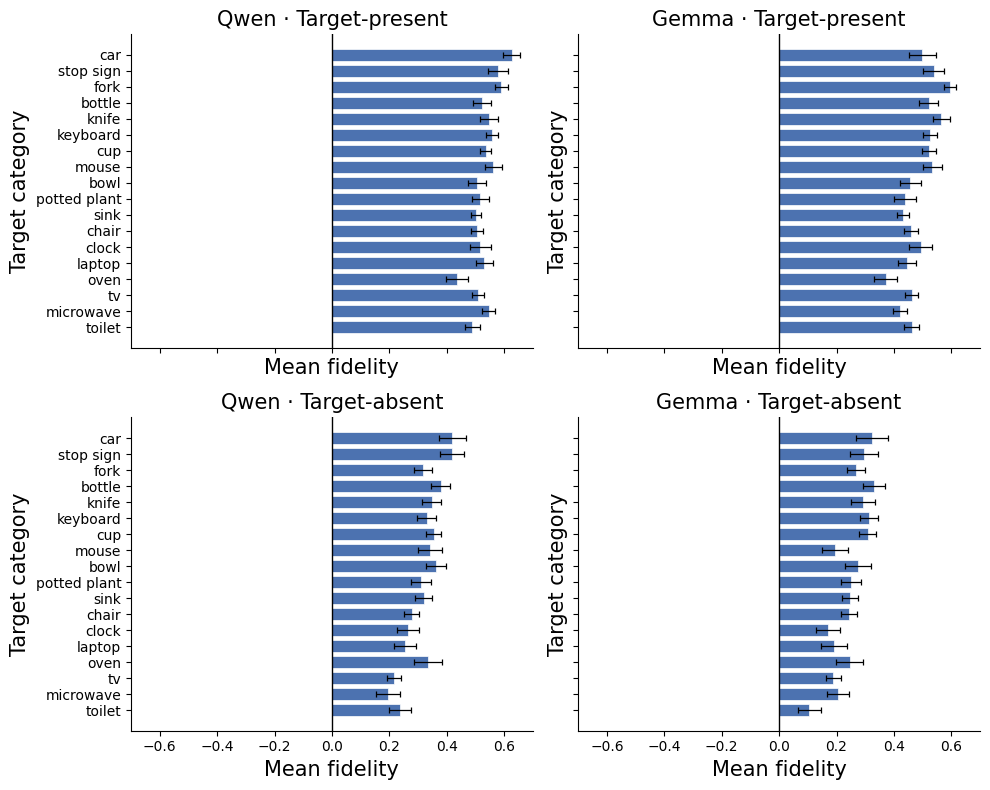

In [14]:
category_plot = category_fidelity_tests.copy()
category_plot["model_label"] = category_plot["model"].map({
    "qwen-thinking": "Qwen",
    "gemma": "Gemma",
})
category_plot["condition_label"] = category_plot["condition"].map({
    "tp": "Target-present",
    "ta": "Target-absent",
})
category_plot["ci95_low"] = category_plot["ci95_low"].astype(float)
category_plot["ci95_high"] = category_plot["ci95_high"].astype(float)

target_order = (
    category_plot
    .groupby("target", sort=False)["mean_fidelity"]
    .mean()
    .sort_values()
    .index
)

x_limit = np.ceil(
    np.abs(category_plot[["ci95_low", "ci95_high"]].to_numpy()).max() * 10
) / 10
panel_order = [
    ("tp", "qwen-thinking"),
    ("tp", "gemma"),
    ("ta", "qwen-thinking"),
    ("ta", "gemma"),
]

fig, axes = plt.subplots(2, 2, figsize=(10, 8), sharex=True, sharey=True)

for ax, (condition, model) in zip(axes.flat, panel_order):
    panel_data = (
        category_plot[
            (category_plot["condition"] == condition)
            & (category_plot["model"] == model)
        ]
        .set_index("target")
        .loc[target_order]
        .reset_index()
    )
    y_positions = np.arange(len(panel_data))
    x_errors = np.vstack([
        panel_data["mean_fidelity"] - panel_data["ci95_low"],
        panel_data["ci95_high"] - panel_data["mean_fidelity"],
    ])

    ax.barh(
        y_positions,
        panel_data["mean_fidelity"],
        xerr=x_errors,
        color="#4C72B0",
        edgecolor="white",
        linewidth=0.5,
        error_kw={"elinewidth": 0.9, "capsize": 2.5, "capthick": 0.9},
    )
    ax.axvline(0, color="black", linewidth=1)
    ax.set_xlim(-x_limit, x_limit)
    ax.set_yticks(y_positions)
    ax.set_yticklabels(panel_data["target"])
    ax.set_title(
        f"{panel_data['model_label'].iloc[0]} · {panel_data['condition_label'].iloc[0]}",
        fontsize=15,
    )
    ax.set_xlabel("Mean fidelity", fontsize=15)
    ax.set_ylabel("Target category", fontsize=15)
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
category_fidelity_fig = fig

## Histograms

Each panel shows the distribution of per-scene fidelity values for one model and condition.

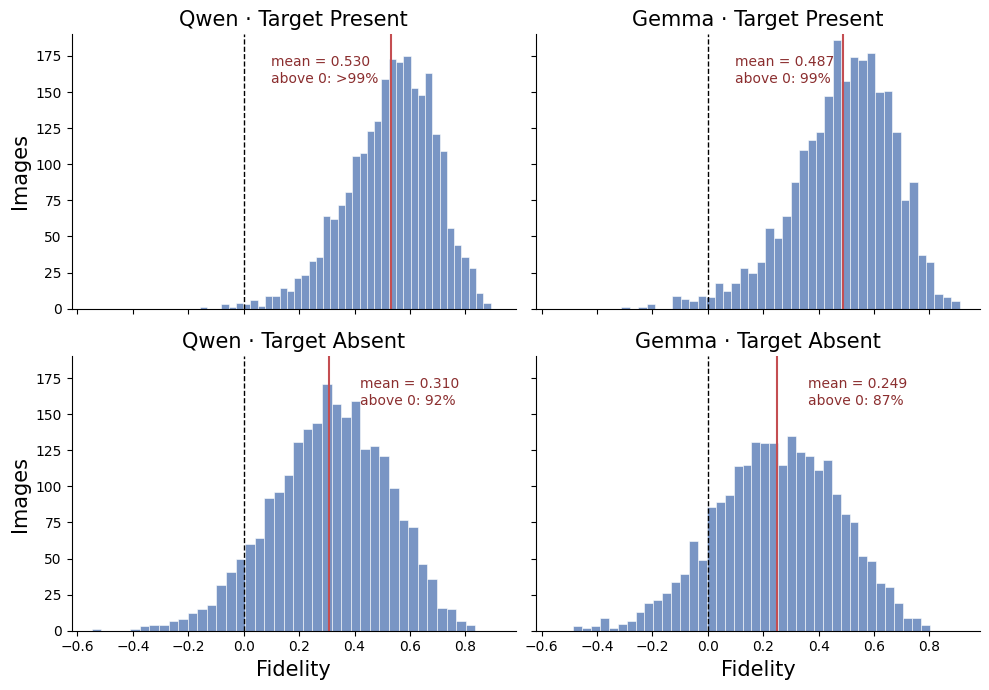

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7), sharex=True, sharey=True)
plot_order = [
    ("qwen-thinking", "tp"),
    ("gemma", "tp"),
    ("qwen-thinking", "ta"),
    ("gemma", "ta"),
]
plot_titles = {
    ("qwen-thinking", "tp"): "Qwen · Target Present",
    ("gemma", "tp"): "Gemma · Target Present",
    ("qwen-thinking", "ta"): "Qwen · Target Absent",
    ("gemma", "ta"): "Gemma · Target Absent",
}

# Custom text positions in each panel's data coordinates: (x, y).
# Adjust these numbers after rendering if a label overlaps the histogram.
annotation_positions = {
    ("qwen-thinking", "tp"): (0.1, 165),
    ("gemma", "tp"): (0.1, 165),
    ("qwen-thinking", "ta"): (0.42, 165),
    ("gemma", "ta"): (0.36, 165),
}

for ax, (model, condition) in zip(axes.flat, plot_order):
    cell_data = output_reorganization_fidelity[
        (output_reorganization_fidelity["model"] == model)
        & (output_reorganization_fidelity["condition"] == condition)
    ]
    mean_fidelity = cell_data["fidelity"].mean()
    positive_pct = 100 * (cell_data["fidelity"] > 0).mean()
    positive_label = ">99%" if positive_pct > 99 else f"{positive_pct:.0f}%"

    sns.histplot(
        data=cell_data,
        x="fidelity",
        bins=40,
        color="#4C72B0",
        edgecolor="white",
        linewidth=0.4,
        ax=ax,
    )
    ax.axvline(0, color="black", linewidth=1, linestyle="--")
    ax.axvline(mean_fidelity, color="#C44E52", linewidth=1.5)
    ax.set_ylim(top=190)

    text_x, text_y = annotation_positions[(model, condition)]
    ax.text(
        text_x,
        text_y,
        f"mean = {mean_fidelity:.3f}\nabove 0: {positive_label}",

        ha="left",
        va="center",
        color="#8B2E2F",
        fontsize=10,
    )

    ax.set_title(
        f"{plot_titles[(model, condition)]}",
        fontsize=15,
    )
    ax.set_xlabel("Fidelity", fontsize=15)
    ax.set_ylabel("Images", fontsize=15)
    ax.spines[["top", "right"]].set_visible(False)

fig.tight_layout()

## Example Reorganization Maps

For the example target-absent image below, the maps show the search-minus-free-view reorganization pattern for the Qwen output arm and for human fixations.

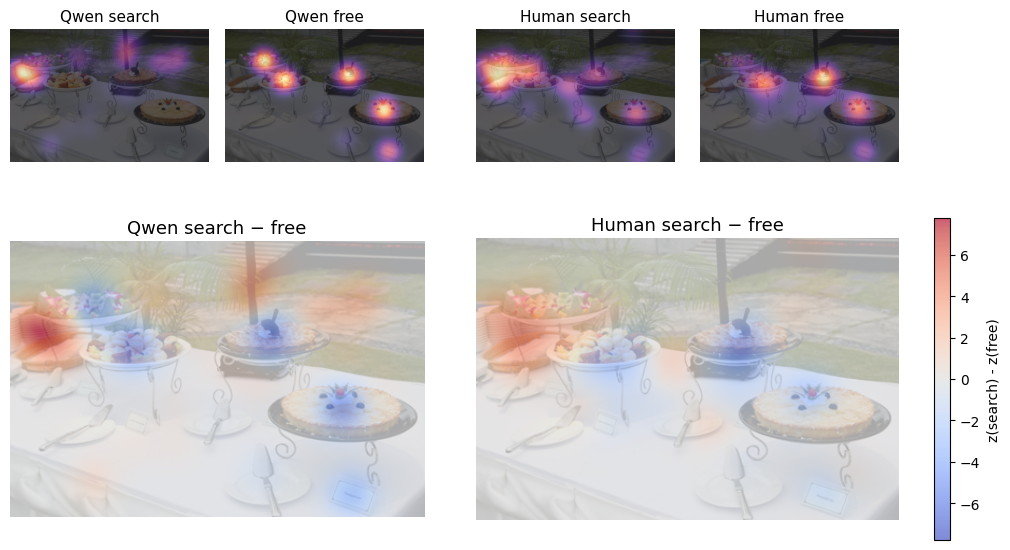

In [11]:
example_model = "qwen-thinking"
example_condition = "ta"
example_picture = ("bottle", "000000085462.jpg")
example_target, example_name = example_picture

example_search_runs = U.get_run_ids(example_model, example_condition, "output", "search")
example_free_runs = U.get_run_ids(example_model, example_condition, "output", "free")

example_model_search_points = U.load_fixations(example_search_runs, mode="vlm")
example_model_free_points = U.load_fixations(example_free_runs, mode="vlm")
example_human_fixations = U.load_fixations(example_search_runs, mode="human")

example_model_search_points = example_model_search_points[
    (example_model_search_points["task"] == example_target)
    & (example_model_search_points["name"] == example_name)
]
example_model_free_points = example_model_free_points[
    (example_model_free_points["task"] == example_target)
    & (example_model_free_points["name"] == example_name)
]
example_human_fixations = example_human_fixations[
    (example_human_fixations["task"] == example_target)
    & (example_human_fixations["name"] == example_name)
]

example_model_search_maps = U.density_maps_from_points(example_model_search_points, mode="vlm")
example_model_free_maps = U.density_maps_from_points(example_model_free_points, mode="vlm")
example_human_search_maps = U.density_maps_from_points(
    example_human_fixations,
    mode="human",
    goal="search",
)
example_human_free_maps = U.density_maps_from_points(
    example_human_fixations,
    mode="human",
    goal="free",
)

example_model_reorganization = U.reorganization_map(
    example_model_search_maps[example_picture],
    example_model_free_maps[example_picture],
)
example_human_reorganization = U.reorganization_map(
    example_human_search_maps[example_picture],
    example_human_free_maps[example_picture],
)


example_image_path = (
    ANALYSIS.parent
    / "data"
    / "COCO-Search18"
    / "TA-images"
    / example_target
    / example_name
)
example_image = Image.open(example_image_path).convert("RGB")
example_image, _, _ = gm.crop_letterbox(example_image)

vlim = max(
    np.abs(example_model_reorganization).max(),
    np.abs(example_human_reorganization).max(),
)

density_maps = [
    ("Qwen search", example_model_search_maps[example_picture]),
    ("Qwen free", example_model_free_maps[example_picture]),
    ("Human search", example_human_search_maps[example_picture]),
    ("Human free", example_human_free_maps[example_picture]),
]
reorganization_maps = [
    ("Qwen search − free", example_model_reorganization),
    ("Human search − free", example_human_reorganization),
]

fig = plt.figure(figsize=(10, 5.6), constrained_layout=True)
grid = fig.add_gridspec(
    2,
    5,
    height_ratios=[0.9, 1.35],
    width_ratios=[1, 1, 0.22, 1, 1],
    hspace=0,
    wspace=0.04,
)

qwen_search_ax = fig.add_subplot(grid[0, 0])
qwen_free_ax = fig.add_subplot(grid[0, 1])
human_search_ax = fig.add_subplot(grid[0, 3])
human_free_ax = fig.add_subplot(grid[0, 4])
qwen_reorg_ax = fig.add_subplot(grid[1, 0:2])
human_reorg_ax = fig.add_subplot(grid[1, 3:5])

for ax, (title, density) in zip(
    [qwen_search_ax, qwen_free_ax, human_search_ax, human_free_ax],
    density_maps,
):
    plot_image = example_image.resize((density.shape[1], density.shape[0]))
    ax.imshow(plot_image, alpha=0.7)
    ax.imshow(density, cmap="magma", vmin=0, vmax=1, alpha=0.65)
    ax.set_title(title, fontsize=11)
    ax.set_box_aspect(density.shape[0] / density.shape[1])
    ax.axis("off")

for ax, (title, reorganization) in zip(
    [qwen_reorg_ax, human_reorg_ax],
    reorganization_maps,
):
    plot_image = example_image.resize((reorganization.shape[1], reorganization.shape[0]))
    ax.imshow(plot_image, alpha=0.7)
    image = ax.imshow(
        reorganization,
        cmap="coolwarm",
        vmin=-vlim,
        vmax=vlim,
        alpha=0.65,
    )
    ax.set_title(title, fontsize=13)
    ax.set_box_aspect(reorganization.shape[0] / reorganization.shape[1])
    ax.axis("off")

fig.colorbar(
    image,
    ax=[qwen_reorg_ax, human_reorg_ax],
    fraction=0.046,
    pad=0.04,
    label="z(search) - z(free)",
)
